# Practical 8: K-Means Clustering

## Aim

To implement the K-Means clustering algorithm using mathematical formulas to group data points into clusters based on their similarity, calculate cluster centroids, and assign a new data point to its nearest cluster.

## 1. Introduction

K-Means is an unsupervised machine learning algorithm used to divide a dataset into a specified number of clusters. It groups similar data points together based on the distance between the points and their cluster centroids.

Unlike supervised learning algorithms, K-Means does not require predefined target labels. It identifies patterns and groups directly from the input data.

In this practical, a dataset containing 12 data points and 3 numerical features is used. The number of clusters is set to $K = 4$, and the first four data points are selected as the initial centroids.

## 2. Dataset Description

The dataset consists of 12 data points, each containing three numerical features:

- Feature 1
- Feature 2
- Feature 3

The dataset can be represented as:

$$
X = \{P_1, P_2, \ldots, P_{12}\}
$$

Each data point is represented as:

$$
P_i = [x_{i1}, x_{i2}, x_{i3}]
$$

For example:

$$
P_1 = [25, 40, 200]
$$

The number of clusters is:

$$
K = 4
$$

The initial centroids are selected from the first four data points:

$$
C_1 = P_1,\quad C_2 = P_2,\quad C_3 = P_3,\quad C_4 = P_4
$$

## 3. Mathematical Formulas

### A. Euclidean Distance

Euclidean distance measures the straight-line distance between a data point and a centroid. It is used to determine how close a data point is to each cluster.

For a dataset containing three features, the distance between point $P_i$ and centroid $C_j$ is calculated as:

$$
d(P_i,C_j) = \sqrt{\sum_{m=1}^{3}(x_{im}-c_{jm})^2}
$$

Expanded form:

$$
d(P_i,C_j) =
\sqrt{
(x_{i1}-c_{j1})^2 +
(x_{i2}-c_{j2})^2 +
(x_{i3}-c_{j3})^2
}
$$

Where:

- $P_i$ represents the data point.
- $C_j$ represents the centroid.
- $x_{im}$ represents feature $m$ of data point $i$.
- $c_{jm}$ represents feature $m$ of centroid $j$.

### B. Cluster Assignment

Each data point is assigned to the cluster whose centroid has the minimum Euclidean distance.

$$
Cluster(P_i) =
\arg\min_{j \in \{1,\ldots,K\}} d(P_i,C_j)
$$

The `argmin` operation returns the index of the centroid with the smallest distance.

### C. Centroid Update

After assigning data points to clusters, each centroid is recalculated as the arithmetic mean of all data points belonging to that cluster.

$$
C_j = \frac{1}{n_j}\sum_{P_i \in Cluster_j}P_i
$$

For three features, the updated centroid is:

$$
C_j =
\left[
\frac{\sum x_{i1}}{n_j},
\frac{\sum x_{i2}}{n_j},
\frac{\sum x_{i3}}{n_j}
\right]
$$

Where $n_j$ is the number of data points assigned to cluster $j$.

### D. Within-Cluster Sum of Squares (WCSS)

WCSS measures the total squared distance between each data point and its assigned centroid. It is commonly used to evaluate the compactness of clusters.

$$
WCSS =
\sum_{j=1}^{K}
\sum_{P_i \in Cluster_j}
\|P_i-C_j\|^2
$$

A lower WCSS generally indicates that data points are closer to their respective centroids.

## 4. Step-by-Step Working of K-Means

### Step 1: Initialize the centroids

Select the number of clusters as $K = 4$. The first four data points are selected as the initial centroids:

$$
C_1 = P_1,\quad C_2 = P_2,\quad C_3 = P_3,\quad C_4 = P_4
$$

### Step 2: Calculate distances

Calculate the Euclidean distance between every data point and all four centroids using the distance formula.

### Step 3: Assign data points to clusters

Assign each data point to the cluster with the minimum distance from its centroid.

### Step 4: Update the centroids

Calculate the mean of each feature for all points assigned to a particular cluster. These mean values form the new centroid.

### Step 5: Repeat the process

Repeat the distance calculation, cluster assignment, and centroid update steps using the newly calculated centroids.

### Step 6: Check convergence

Continue the iterations until the centroids stop changing significantly or the maximum number of iterations is reached.

### Step 7: Predict the cluster for a new data point

Accept three feature values from the user. Calculate the Euclidean distance between the new data point and each final centroid. Assign the point to the cluster with the minimum distance.

## 5. Convergence Condition

The algorithm converges when the centroids remain unchanged between consecutive iterations.

$$
C_j^{(t+1)} = C_j^{(t)}
$$

Where:

- $C_j^{(t)}$ is the centroid at iteration $t$.
- $C_j^{(t+1)}$ is the centroid at the next iteration.

In practical implementations, a small numerical tolerance may be used to determine whether the centroids have converged.

## 6. Applications of K-Means Clustering

1. **Customer segmentation:** Grouping customers based on purchasing behaviour.
2. **Student performance analysis:** Grouping students according to academic performance.
3. **Image segmentation:** Grouping pixels with similar characteristics.
4. **Document clustering:** Grouping similar documents and articles.
5. **Business analytics:** Identifying patterns in sales and customer data.
6. **Data analysis:** Discovering natural groupings in numerical datasets.

## 7. Advantages

- Simple and easy to understand and implement.
- Efficient for relatively large numerical datasets.
- Does not require labelled training data.
- Produces clear cluster assignments and centroids.
- Can be applied to many practical clustering problems.

## 8. Limitations

- The number of clusters, $K$, must be specified in advance.
- The results may depend on the initial centroid selection.
- Outliers can significantly affect the positions of centroids.
- Features with larger numerical scales can dominate distance calculations.
- The algorithm may converge to a local optimum rather than the globally optimal clustering.
- It works best when clusters are reasonably compact and well separated.

## 9. Libraries Used

- **NumPy:** Used for numerical calculations, arrays, Euclidean distances, and centroid updates.
- **Pandas:** Used to represent the dataset, distances, centroids, and cluster assignments in tabular form.
- **Matplotlib:** Used to visualize the clusters and centroids using a three-dimensional scatter plot.

The K-Means algorithm in this practical is implemented through explicit distance calculations, cluster assignments, and mean-based centroid updates instead of using a ready-made K-Means implementation from Scikit-learn.

## 10. Result

The K-Means clustering algorithm was implemented successfully on a dataset containing 12 data points and 3 numerical features with $K = 4$. The program calculated Euclidean distances, assigned data points to their nearest centroids, updated the centroids iteratively until convergence, calculated WCSS, visualized the final clusters, and predicted the cluster of a user-provided data point.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = np.array([
    [25, 40, 200],
    [30, 50, 220],
    [24, 38, 180],
    [80, 90, 800],
    [82, 85, 780],
    [78, 88, 820],
    [45, 55, 300],
    [43, 53, 320],
    [46, 50, 310],
    [150, 160, 1200],
    [148, 155, 1180],
    [152, 162, 1220]
], dtype=float)

point_names = [f"P{i}" for i in range(1, 13)]

df = pd.DataFrame(
    data,
    columns=["Feature1", "Feature2", "Feature3"],
    index=point_names
)

print("Original Dataset:")
display(df)

Original Dataset:


,Feature1,Feature2,Feature3
P1,25.0,40.0,200.0
P2,30.0,50.0,220.0
P3,24.0,38.0,180.0
P4,80.0,90.0,800.0
P5,82.0,85.0,780.0
P6,78.0,88.0,820.0
P7,45.0,55.0,300.0
P8,43.0,53.0,320.0
P9,46.0,50.0,310.0
P10,150.0,160.0,1200.0


In [3]:
K = 4

centroids = data[:K].copy()

centroid_names = ["C1", "C2", "C3", "C4"]

print("Initial Centroids:")
display(pd.DataFrame(
    centroids,
    columns=["Feature1", "Feature2", "Feature3"],
    index=centroid_names
))

Initial Centroids:


,Feature1,Feature2,Feature3
C1,25.0,40.0,200.0
C2,30.0,50.0,220.0
C3,24.0,38.0,180.0
C4,80.0,90.0,800.0


In [4]:
def euclidean_distance(point, centroid):
    squared_differences = (point - centroid) ** 2
    distance = np.sqrt(np.sum(squared_differences))
    return distance

# Example calculation: distance between P1 and C1
example_distance = euclidean_distance(data[0], centroids[0])

print("Point P1:", data[0])
print("Centroid C1:", centroids[0])
print("Euclidean Distance:", example_distance)

Point P1: [ 25.  40. 200.]
Centroid C1: [ 25.  40. 200.]
Euclidean Distance: 0.0


In [5]:
distance_matrix = np.zeros((len(data), K))

for i in range(len(data)):
    for j in range(K):
        distance_matrix[i, j] = euclidean_distance(data[i], centroids[j])

distance_df = pd.DataFrame(
    distance_matrix,
    columns=centroid_names,
    index=point_names
)

print("Distances of Every Point from Each Initial Centroid:")
display(distance_df.round(3))

Distances of Every Point from Each Initial Centroid:


,C1,C2,C3,C4
P1,0.000,22.913,20.125,604.587
P2,22.913,0.000,42.190,583.524
P3,20.125,42.190,0.000,624.692
P4,604.587,583.524,624.692,0.000
P5,584.529,563.497,604.626,20.712
P6,624.110,603.115,644.217,20.199
P7,103.078,81.548,123.004,502.444
P8,122.037,100.886,142.077,482.844
P9,112.432,91.411,132.393,492.804
P10,1014.901,993.428,1034.969,412.068


In [6]:
cluster_assignments = np.argmin(distance_matrix, axis=1)

assignment_df = pd.DataFrame({
    "Feature1": data[:, 0],
    "Feature2": data[:, 1],
    "Feature3": data[:, 2],
    "Nearest_Centroid": [
        centroid_names[c] for c in cluster_assignments
    ]
}, index=point_names)

print("Initial Cluster Assignments:")
display(assignment_df)

Initial Cluster Assignments:


,Feature1,Feature2,Feature3,Nearest_Centroid
P1,25.0,40.0,200.0,C1
P2,30.0,50.0,220.0,C2
P3,24.0,38.0,180.0,C3
P4,80.0,90.0,800.0,C4
P5,82.0,85.0,780.0,C4
P6,78.0,88.0,820.0,C4
P7,45.0,55.0,300.0,C2
P8,43.0,53.0,320.0,C2
P9,46.0,50.0,310.0,C2
P10,150.0,160.0,1200.0,C4


In [7]:
new_centroids = np.zeros_like(centroids)

for cluster in range(K):
    cluster_points = data[cluster_assignments == cluster]

    if len(cluster_points) > 0:
        new_centroids[cluster] = np.mean(cluster_points, axis=0)
    else:
        new_centroids[cluster] = centroids[cluster]

print("Updated Centroids After First Iteration:")

display(pd.DataFrame(
    new_centroids,
    columns=["Feature1", "Feature2", "Feature3"],
    index=centroid_names
))

Updated Centroids After First Iteration:


,Feature1,Feature2,Feature3
C1,25.0,40.000000,200.0
C2,41.0,52.000000,287.5
C3,24.0,38.000000,180.0
C4,115.0,123.333333,1000.0


In [8]:
for cluster in range(K):
    cluster_points = data[cluster_assignments == cluster]

    print(f"\nCluster C{cluster + 1}")

    if len(cluster_points) == 0:
        print("No points assigned to this cluster.")
        continue

    assigned_names = [
        point_names[i]
        for i in range(len(data))
        if cluster_assignments[i] == cluster
    ]

    print("Assigned Points:", assigned_names)
    print("Number of Points:", len(cluster_points))

    for feature_index in range(data.shape[1]):
        values = cluster_points[:, feature_index]

        print(
            f"Feature {feature_index + 1}: "
            f"({ ' + '.join(map(str, values)) }) / {len(values)} "
            f"= {np.mean(values):.3f}"
        )

    print("New Centroid:", np.mean(cluster_points, axis=0))


Cluster C1
Assigned Points: ['P1']
Number of Points: 1
Feature 1: (25.0) / 1 = 25.000
Feature 2: (40.0) / 1 = 40.000
Feature 3: (200.0) / 1 = 200.000
New Centroid: [ 25.  40. 200.]

Cluster C2
Assigned Points: ['P2', 'P7', 'P8', 'P9']
Number of Points: 4
Feature 1: (30.0 + 45.0 + 43.0 + 46.0) / 4 = 41.000
Feature 2: (50.0 + 55.0 + 53.0 + 50.0) / 4 = 52.000
Feature 3: (220.0 + 300.0 + 320.0 + 310.0) / 4 = 287.500
New Centroid: [ 41.   52.  287.5]

Cluster C3
Assigned Points: ['P3']
Number of Points: 1
Feature 1: (24.0) / 1 = 24.000
Feature 2: (38.0) / 1 = 38.000
Feature 3: (180.0) / 1 = 180.000
New Centroid: [ 24.  38. 180.]

Cluster C4
Assigned Points: ['P4', 'P5', 'P6', 'P10', 'P11', 'P12']
Number of Points: 6
Feature 1: (80.0 + 82.0 + 78.0 + 150.0 + 148.0 + 152.0) / 6 = 115.000
Feature 2: (90.0 + 85.0 + 88.0 + 160.0 + 155.0 + 162.0) / 6 = 123.333
Feature 3: (800.0 + 780.0 + 820.0 + 1200.0 + 1180.0 + 1220.0) / 6 = 1000.000
New Centroid: [ 115.          123.33333333 1000.        ]


In [9]:
max_iterations = 100
tolerance = 1e-8

centroids = data[:K].copy()
history = []

for iteration in range(max_iterations):
    # Step 1: Calculate distances
    distances = np.zeros((len(data), K))

    for i in range(len(data)):
        for j in range(K):
            distances[i, j] = euclidean_distance(data[i], centroids[j])

    # Step 2: Assign each point to the nearest centroid
    assignments = np.argmin(distances, axis=1)

    # Step 3: Calculate new centroids
    updated_centroids = centroids.copy()

    for cluster in range(K):
        cluster_points = data[assignments == cluster]

        if len(cluster_points) > 0:
            updated_centroids[cluster] = np.mean(
                cluster_points, axis=0
            )

    history.append({
        "Iteration": iteration + 1,
        "Centroids": updated_centroids.copy(),
        "Assignments": assignments.copy()
    })

    print(f"\nIteration {iteration + 1}")
    display(pd.DataFrame(
        updated_centroids,
        columns=["Feature1", "Feature2", "Feature3"],
        index=centroid_names
    ))

    # Stop if centroids have converged
    if np.allclose(
        centroids, updated_centroids,
        atol=tolerance, rtol=0
    ):
        centroids = updated_centroids
        print("Centroids converged.")
        break

    centroids = updated_centroids

final_centroids = centroids.copy()
final_assignments = assignments.copy()


Iteration 1


,Feature1,Feature2,Feature3
C1,25.0,40.000000,200.0
C2,41.0,52.000000,287.5
C3,24.0,38.000000,180.0
C4,115.0,123.333333,1000.0



Iteration 2


,Feature1,Feature2,Feature3
C1,27.500000,45.000000,210.0
C2,44.666667,52.666667,310.0
C3,24.000000,38.000000,180.0
C4,115.000000,123.333333,1000.0



Iteration 3


,Feature1,Feature2,Feature3
C1,27.500000,45.000000,210.0
C2,44.666667,52.666667,310.0
C3,24.000000,38.000000,180.0
C4,115.000000,123.333333,1000.0


Centroids converged.


In [10]:
final_results = df.copy()

final_results["Cluster"] = [
    f"Cluster {c + 1}" for c in final_assignments
]

print("Final Cluster Assignments:")
display(final_results.sort_values("Cluster"))

print("\nFinal Centroids:")
display(pd.DataFrame(
    final_centroids,
    columns=["Feature1", "Feature2", "Feature3"],
    index=centroid_names
))

for cluster in range(K):
    members = [
        point_names[i]
        for i in range(len(data))
        if final_assignments[i] == cluster
    ]

    print(f"Cluster {cluster + 1}: {members}")

Final Cluster Assignments:


,Feature1,Feature2,Feature3,Cluster
P1,25.0,40.0,200.0,Cluster 1
P2,30.0,50.0,220.0,Cluster 1
P7,45.0,55.0,300.0,Cluster 2
P8,43.0,53.0,320.0,Cluster 2
P9,46.0,50.0,310.0,Cluster 2
P3,24.0,38.0,180.0,Cluster 3
P4,80.0,90.0,800.0,Cluster 4
P5,82.0,85.0,780.0,Cluster 4
P6,78.0,88.0,820.0,Cluster 4
P10,150.0,160.0,1200.0,Cluster 4



Final Centroids:


,Feature1,Feature2,Feature3
C1,27.500000,45.000000,210.0
C2,44.666667,52.666667,310.0
C3,24.000000,38.000000,180.0
C4,115.000000,123.333333,1000.0


Cluster 1: ['P1', 'P2']
Cluster 2: ['P7', 'P8', 'P9']
Cluster 3: ['P3']
Cluster 4: ['P4', 'P5', 'P6', 'P10', 'P11', 'P12']


In [11]:
wcss = 0.0

for i in range(len(data)):
    assigned_centroid = final_centroids[final_assignments[i]]
    squared_distance = np.sum(
        (data[i] - assigned_centroid) ** 2
    )
    wcss += squared_distance

print(f"Final WCSS: {wcss:.3f}")

Final WCSS: 257117.167


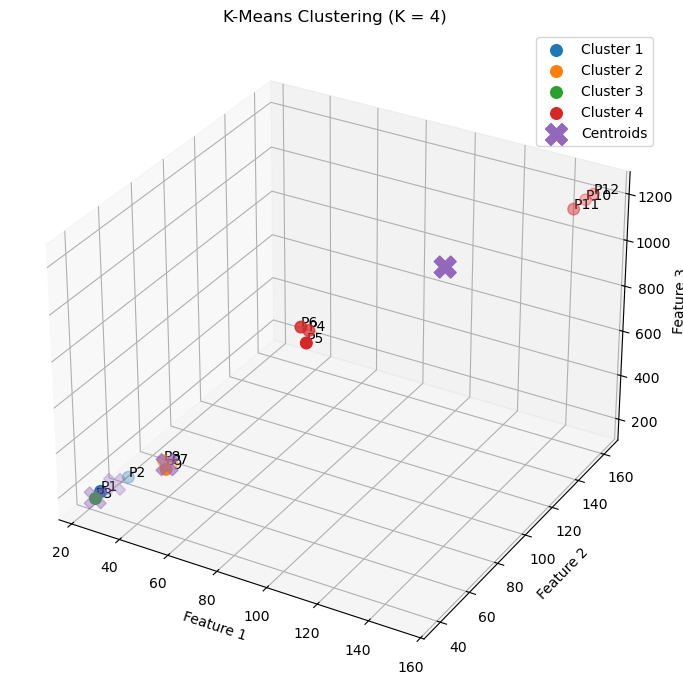

In [12]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

for cluster in range(K):
    cluster_points = data[final_assignments == cluster]

    if len(cluster_points) > 0:
        ax.scatter(
            cluster_points[:, 0],
            cluster_points[:, 1],
            cluster_points[:, 2],
            label=f"Cluster {cluster + 1}",
            s=70
        )

ax.scatter(
    final_centroids[:, 0],
    final_centroids[:, 1],
    final_centroids[:, 2],
    marker="X",
    s=250,
    label="Centroids"
)

for i, point in enumerate(data):
    ax.text(point[0], point[1], point[2], point_names[i])

ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_zlabel("Feature 3")
ax.set_title("K-Means Clustering (K = 4)")
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
print("Enter the values for a new data point.")

f1 = float(input("Enter Feature 1: "))
f2 = float(input("Enter Feature 2: "))
f3 = float(input("Enter Feature 3: "))

new_point = np.array([f1, f2, f3])

print("\nNew Point:", new_point)

print("\nDistance from Each Final Centroid:")

new_distances = []

for cluster in range(K):
    distance = euclidean_distance(
        new_point, final_centroids[cluster]
    )
    new_distances.append(distance)

    print(f"Centroid C{cluster + 1}: {distance:.3f}")

predicted_cluster = int(np.argmin(new_distances))

print("\nPredicted Cluster:", predicted_cluster + 1)
print("Nearest Centroid:", centroid_names[predicted_cluster])

Enter the values for a new data point.

New Point: [ 44.  54. 305.]

Distance from Each Final Centroid:
Centroid C1: 96.841
Centroid C2: 5.217
Centroid C3: 127.597
Centroid C4: 702.049

Predicted Cluster: 2
Nearest Centroid: C2
